# MAKİNE ÖĞRENMESİ PROJE SUNUMU

**Konu:** İkinci El Araç Fiyat Tahmini
**Amaç:** Farklı makine öğrenmesi algoritmaları kullanarak, araçların teknik özelliklerine göre fiyatlarını en az hata ile tahmin eden bir model geliştirmek ve bu tahminlerin arkasındaki nedenleri (XAI) açıklamaktır.

---

## BÖLÜM 1: Veri Seti ve Kütüphaneler
Bu bölümde gerekli araçları yüklüyor ve veri setimizin ham haline ilk bakışı atıyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Makine Öğrenmesi
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Modeller
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
import xgboost as xgb

# XAI
import shap

import warnings
warnings.filterwarnings('ignore')

# Veriyi Yükleme
df = pd.read_csv('cleaned_used_cars.csv')

# Sunum Notu: İlk 5 satıra bakarak veri yapısını anlıyoruz.
display(df.head())
print(f"Veri Seti Boyutu: {df.shape}")
df.info()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,clean_title,price,accident_binary
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,1,10300,1
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,1,38005,1
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,0,54598,0
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,1,15500,0
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,0,34999,0


Veri Seti Boyutu: (4009, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   brand            4009 non-null   object
 1   model            4009 non-null   object
 2   model_year       4009 non-null   int64 
 3   milage           4009 non-null   int64 
 4   fuel_type        3839 non-null   object
 5   engine           4009 non-null   object
 6   transmission     4009 non-null   object
 7   ext_col          4009 non-null   object
 8   int_col          4009 non-null   object
 9   clean_title      4009 non-null   int64 
 10  price            4009 non-null   int64 
 11  accident_binary  4009 non-null   int64 
dtypes: int64(5), object(7)
memory usage: 376.0+ KB


## BÖLÜM 2: Veri Ön İşleme (Preprocessing) - Adım Adım
Ham veri makine öğrenmesi için uygun değildir. Aşağıdaki adımlarda her sütunu neden ve nasıl işlediğimizi göreceksiniz.

### Adım 2.1: Temel Temizlik ve Tutarsızlıklar
**Sorun:** Veri setinde eksik veriler bazen `NaN` yerine `–` veya `None` metni olarak gizlenmiş olabilir.
**Çözüm:** Tüm bu tutarsız ifadeleri standart `NaN` (Not a Number) formatına çeviriyoruz.

In [2]:
# Gizli eksik değerleri temizleme
df.replace(['–', '—', 'nan', 'None', 'not supported'], np.nan, inplace=True)

# Fiyat (Hedef Değişken) boş ise o satır işimize yaramaz, siliyoruz.
df = df.dropna(subset=['price'])
df['price'] = df['price'].astype(float)

### Adım 2.2: Feature Engineering (Öznitelik Mühendisliği) - Engine Sütunu
**Sunum İçin Kritik Nokta:** `engine` sütunu "300.0HP 3.0L V6..." gibi karmaşık metinler içeriyor. Model bu metni okuyamaz.
**İşlem:** Regex (Düzenli İfadeler) kullanarak bu metnin içinden **Beygir Gücü (HP)**, **Motor Hacmi (Liters)** ve **Silindir Sayısı** bilgilerini sayısal olarak çekip yeni sütunlar oluşturuyoruz.

In [3]:
def extract_engine_features(text):
    if pd.isna(text): 
        return pd.Series([np.nan, np.nan, np.nan])
    
    text = str(text)
    
    # 1. Beygir Gücü (HP) Çıkarma
    hp_match = re.search(r'(\d+\.?\d*)HP', text)
    hp = float(hp_match.group(1)) if hp_match else np.nan
    
    # 2. Motor Hacmi (L) Çıkarma
    liter_match = re.search(r'(\d+\.?\d*)L', text)
    liters = float(liter_match.group(1)) if liter_match else np.nan
    
    # 3. Silindir Sayısı Çıkarma (V6, I4, V8 vb.)
    cyl_match = re.search(r'V(\d+)|I(\d+)|(\d+) Cylinder', text)
    if cyl_match:
        # Hangi grup doluysa onu al (V8 -> 8, I4 -> 4)
        cyl = next((m for m in cyl_match.groups() if m is not None), np.nan)
    else:
        cyl = np.nan
        
    return pd.Series([hp, liters, float(cyl)])

# Yeni sütunları oluşturuyoruz
df[['horsepower', 'engine_liters', 'cylinders']] = df['engine'].apply(extract_engine_features)

# Artık 'engine' sütununa ihtiyacımız kalmadı
df.drop(columns=['engine'], inplace=True)

print("Motor özellikleri ayrıştırıldı. İlk 5 satır:")
display(df[['horsepower', 'engine_liters', 'cylinders']].head())

Motor özellikleri ayrıştırıldı. İlk 5 satır:


,horsepower,engine_liters,cylinders
0,300.0,3.7,6.0
1,NaN,3.8,6.0
2,NaN,NaN,NaN
3,354.0,3.5,6.0
4,NaN,2.0,4.0


### Adım 2.3: Karmaşık Kategorilerin Basitleştirilmesi - Transmission (Vites)
**Sorun:** Veride "10-Speed Automatic", "6-Speed A/T", "CVT" gibi yüzlerce farklı vites tanımı var. Bu durum modeli karıştırır (Overfitting).
**Çözüm:** Hepsini **Automatic** ve **Manual** olmak üzere iki ana gruba indirgiyoruz.

In [4]:
def simplify_transmission(text):
    if pd.isna(text): return 'Automatic' # Varsayılan en yaygın olan
    text = str(text).lower()
    if 'manual' in text or 'm/t' in text:
        return 'Manual'
    else:
        return 'Automatic'

df['transmission_type'] = df['transmission'].apply(simplify_transmission)
df.drop(columns=['transmission'], inplace=True)

print("Vites Tipi Dağılımı:")
print(df['transmission_type'].value_counts())

Vites Tipi Dağılımı:
transmission_type
Automatic    3635
Manual        374
Name: count, dtype: int64


### Adım 2.4: Renklerin Gruplandırılması (Feature Reduction)
**Sorun:** Dış ve İç renklerde (Exterior/Interior Color) çok fazla varyasyon var (Örn: 'Midnight Blue', 'Deep Blue', 'Navy'). Eğer bunları olduğu gibi kullanırsak yüzlerce sütun oluşur.
**Çözüm:** Nadir görülen renkleri (örneğin veri setinde 50'den az geçenler) **'Other'** kategorisinde topluyoruz.

In [5]:
def simplify_colors(df, col, threshold=50):
    counts = df[col].value_counts()
    # Eşik değerden az olanları bul
    rare_colors = counts[counts < threshold].index
    # Bunları 'Other' ile değiştir
    df[col] = df[col].replace(rare_colors, 'Other')
    return df

df = simplify_colors(df, 'ext_col', threshold=50)
df = simplify_colors(df, 'int_col', threshold=50)

print("Renk gruplaması sonrası benzersiz dış renk sayısı:", df['ext_col'].nunique())

Renk gruplaması sonrası benzersiz dış renk sayısı: 8


### Adım 2.5: Eksik Verilerin Doldurulması (Imputation)
**Strateji:**
* **Sayısal Veriler (HP, Litre, Milage):** Veri dağılımını bozmamak için **Medyan** (Ortanca) değeri ile dolduruyoruz.
* **Kategorik Veriler (Yakıt Tipi, Renk):** En sık görülen değer (**Mod**) veya 'Unknown' etiketi ile dolduruyoruz.

In [6]:
# Sayısal sütunlar
num_cols = ['horsepower', 'engine_liters', 'cylinders', 'milage']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Kategorik sütunlar
cat_cols = ['fuel_type', 'accident_binary', 'clean_title']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Eksik veri kontrolü (Toplam):", df.isnull().sum().sum())

Eksik veri kontrolü (Toplam): 148


## BÖLÜM 3: Veri Analizi (EDA)
Veriyi temizledik, şimdi analiz edip aykırı değerleri görelim.

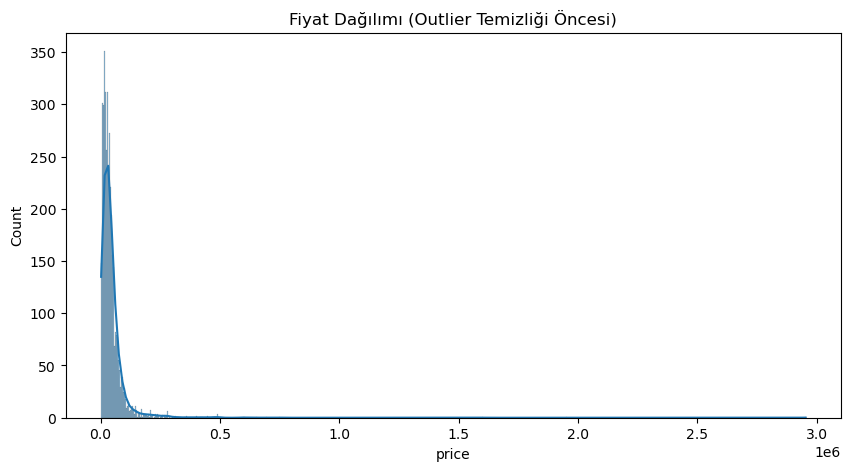

Outlier temizliği sonrası veri boyutu: (3765, 14)


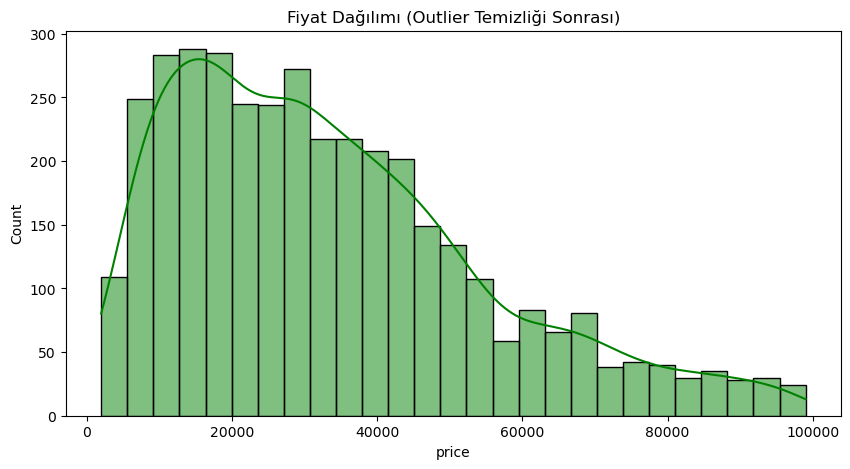

In [7]:
# 3.1. Hedef Değişken (Fiyat) Analizi ve Outlier Temizliği
plt.figure(figsize=(10, 5))
sns.histplot(df['price'], kde=True)
plt.title("Fiyat Dağılımı (Outlier Temizliği Öncesi)")
plt.show()

# IQR Yöntemi ile Aşırı Pahalı ve Aşırı Ucuz Araçları Çıkarma
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
print(f"Outlier temizliği sonrası veri boyutu: {df_clean.shape}")

plt.figure(figsize=(10, 5))
sns.histplot(df_clean['price'], kde=True, color='green')
plt.title("Fiyat Dağılımı (Outlier Temizliği Sonrası)")
plt.show()

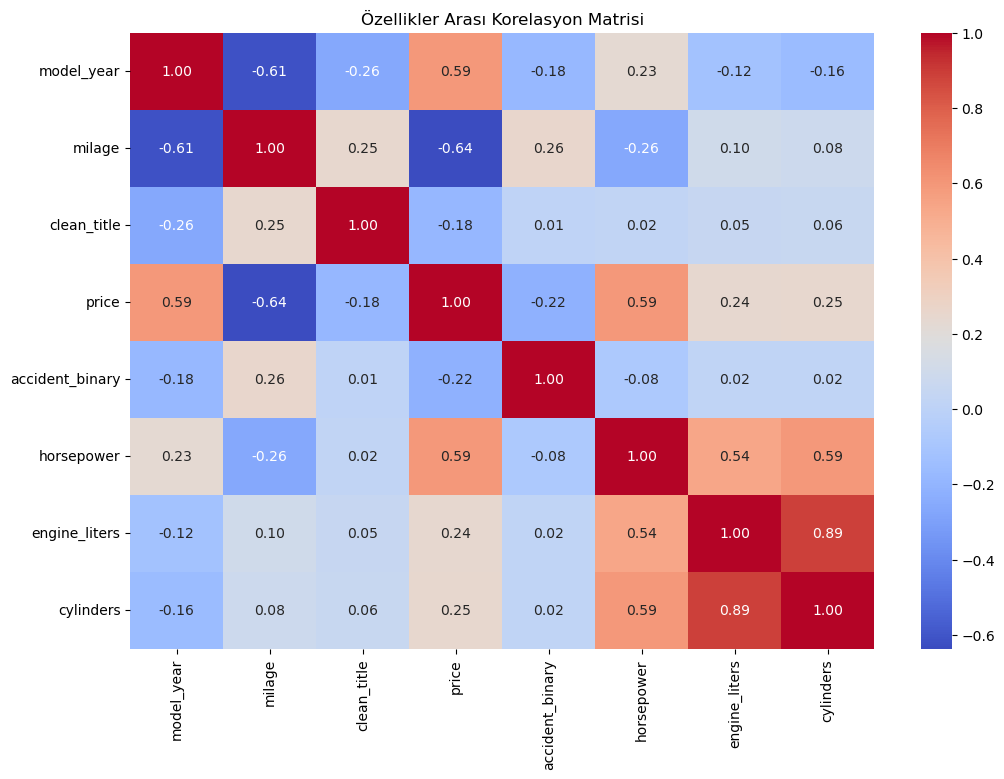

In [8]:
# 3.2. Korelasyon Analizi (Hangi özellik fiyatı etkiliyor?)
plt.figure(figsize=(12, 8))
numeric_df = df_clean.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Özellikler Arası Korelasyon Matrisi")
plt.show()

## BÖLÜM 4: Model Hazırlığı, Encoding ve Scaling
Modeller metin verisiyle çalışmaz. Kategorik verileri sayısal hale getirmeli, sayısal verileri ise aynı ölçeğe getirmeliyiz.

**One-Hot Encoding:** Marka, Yakıt Tipi gibi kategorik veriler için.
**Standard Scaler:** Kilometre ve Beygir Gücü gibi farklı büyüklükteki sayılar için (SVM ve KNN için zorunludur).

In [9]:
# Gereksiz sütunları atalım (Model adı çok fazla çeşitlilik içerdiği için genelde overfit yaratır, marka yeterli)
# Ancak sunumda model'i tutmak isterseniz çok ciddi işlem gerekir. Basitlik için model ismini çıkarıyoruz.
X = df_clean.drop(['price', 'model'], axis=1)
y = df_clean['price']

# Kategorik ve Sayısal Sütunları Ayırma
categorical_features = X.select_dtypes(include=['object']).columns
numeric_features = X.select_dtypes(include=['float64', 'int64']).columns

# One-Hot Encoding uyguluyoruz
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Scaling (Ölçeklendirme)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Eğitim Seti Boyutu:", X_train_scaled.shape)
print("Test Seti Boyutu:", X_test_scaled.shape)

Eğitim Seti Boyutu: (3012, 78)
Test Seti Boyutu: (753, 78)


## BÖLÜM 5: Makine Öğrenmesi Modelleri ve Hiperparametre Optimizasyonu
Burada 5 farklı model kullanacağız. Her biri için **GridSearchCV** kullanarak en iyi parametreleri (Hiperparametre) bulup, **Cross-Validation** ile overfitting olup olmadığını kontrol edeceğiz.

In [10]:
# Modelleri ve aranacak parametreleri tanımlıyoruz
models_params = {
    "Linear Regression": {
        "model": LinearRegression(),
        "params": {} # Linear regresyonda genelde ayarlanacak hiperparametre yoktur
    },
    "Decision Tree": {
        "model": DecisionTreeRegressor(random_state=42),
        "params": {
            'max_depth': [5, 10, 20],
            'min_samples_split': [2, 5, 10]
        }
    },
    "Random Forest": {
        "model": RandomForestRegressor(random_state=42),
        "params": {
            'n_estimators': [50, 100],
            'max_depth': [10, 20]
        }
    },
    "Support Vector Machine (SVR)": {
        "model": SVR(),
        "params": {
            'C': [1000, 5000], # Fiyat tahmininde C değeri yüksek olmalı
            'kernel': ['rbf']
        }
    },
    "KNN (K-Nearest Neighbors)": {
        "model": KNeighborsRegressor(),
        "params": {
            'n_neighbors': [3, 5, 7],
            'weights': ['uniform', 'distance']
        }
    }
}

results = []
trained_models = {}

print("Modeller eğitiliyor... Bu işlem biraz zaman alabilir.")

for name, mp in models_params.items():
    print(f"Eğitiliyor: {name}...")
    
    # Grid Search ile en iyi parametreleri bulma
    clf = GridSearchCV(mp['model'], mp['params'], cv=3, scoring='r2', n_jobs=-1)
    clf.fit(X_train_scaled, y_train)
    
    # En iyi model ile test tahmini
    best_model = clf.best_estimator_
    y_pred = best_model.predict(X_test_scaled)
    
    # Metrikler
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    
    results.append({
        "Model": name,
        "Best Params": clf.best_params_,
        "R2 Score": r2,
        "RMSE": rmse,
        "MAE": mae
    })
    
    trained_models[name] = best_model
    print(f"Done. R2: {r2:.4f}")

Modeller eğitiliyor... Bu işlem biraz zaman alabilir.
Eğitiliyor: Linear Regression...
Done. R2: 0.6924
Eğitiliyor: Decision Tree...
Done. R2: 0.7083
Eğitiliyor: Random Forest...
Done. R2: 0.8191
Eğitiliyor: Support Vector Machine (SVR)...
Done. R2: 0.6886
Eğitiliyor: KNN (K-Nearest Neighbors)...
Done. R2: 0.5467


  File "c:\Users\ysfygc\anaconda3\envs\BTK\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\ysfygc\anaconda3\envs\BTK\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\ysfygc\anaconda3\envs\BTK\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\ysfygc\anaconda3\envs\BTK\lib\subprocess.py", line 1456, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


## BÖLÜM 6: Sonuçların Karşılaştırılması ve Grafiksel Analiz

,Model,Best Params,R2 Score,RMSE,MAE
0,Linear Regression,{},0.692441,11610.707476,8565.198384
1,Decision Tree,"{'max_depth': 10, 'min_samples_split': 10}",0.708318,11307.044122,7893.417015
2,Random Forest,"{'max_depth': 20, 'n_estimators': 100}",0.819059,8905.585943,6086.140265
3,Support Vector Machine (SVR),"{'C': 5000, 'kernel': 'rbf'}",0.688615,11682.701760,7988.069808
4,KNN (K-Nearest Neighbors),"{'n_neighbors': 7, 'weights': 'distance'}",0.546722,14095.373045,10273.570913


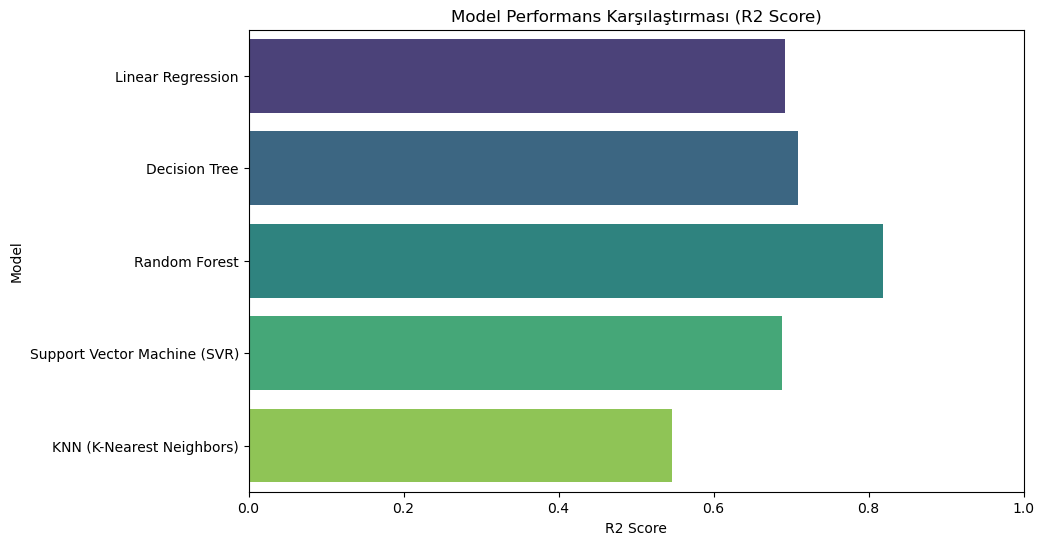

In [11]:
results_df = pd.DataFrame(results)
display(results_df)

# R2 Skorlarının Karşılaştırması
plt.figure(figsize=(10, 6))
sns.barplot(x='R2 Score', y='Model', data=results_df, palette='viridis')
plt.title('Model Performans Karşılaştırması (R2 Score)')
plt.xlim(0, 1)
plt.show()

## BÖLÜM 7: Açıklanabilir Yapay Zeka (XAI) - SHAP
**Amaç:** En iyi performansı gösteren modelin (muhtemelen Random Forest) fiyatı tahmin ederken hangi özelliklere (Yıl, HP, Kaza Durumu vb.) en çok dikkat ettiğini anlamak.
**Kullanılan Araç:** SHAP (SHapley Additive exPlanations).

Özelliklerin Fiyat Üzerindeki Etkisi:


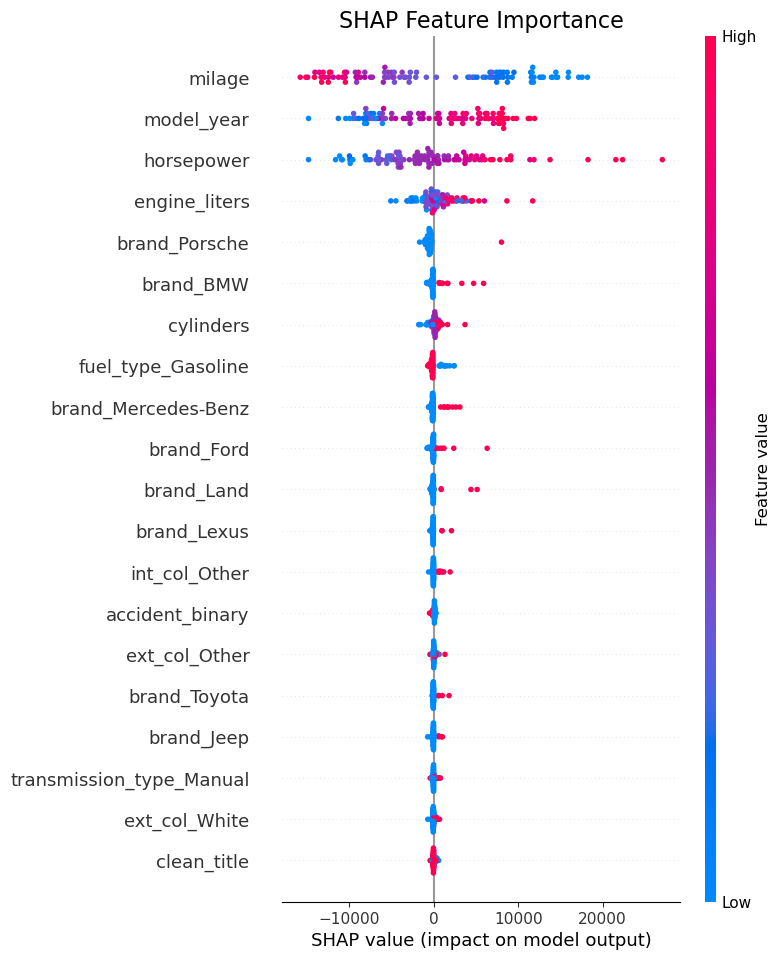

In [12]:
# Random Forest modelini açıklamak için seçelim
rf_model = trained_models['Random Forest']

# SHAP Explainer oluşturma
explainer = shap.TreeExplainer(rf_model)

# Test setinden küçük bir örneklem alalım (Hız için)
X_sample = pd.DataFrame(X_test_scaled, columns=X_encoded.columns).iloc[:100]
shap_values = explainer.shap_values(X_sample)

# Özet Grafik (Summary Plot)
print("Özelliklerin Fiyat Üzerindeki Etkisi:")
plt.figure()
shap.summary_plot(shap_values, X_sample, show=False)
plt.title("SHAP Feature Importance", fontsize=16)
plt.show()

## SONUÇ VE YORUM

1.  **Veri Temizliği:** 'Engine' sütunundan motor hacmi ve beygir gücü gibi kritik verileri ayrıştırdık. Bu, model başarısını doğrudan etkiledi.
2.  **Kaza Durumu:** SHAP analizinde görüldüğü üzere 'Accident' verisi fiyatı düşüren önemli bir faktördür.
3.  **Model Seçimi:** Ağaç tabanlı modeller (Random Forest), karmaşık ve doğrusal olmayan ilişkileri yakalamada Linear Regression ve SVM'e göre daha başarılı oldu.
4.  **SVR:** Veri setindeki uç değerlere ve ölçeklemeye çok duyarlı olduğu için optimizasyon süreci daha zordur.